# Random forests for heart disease prediction (Python)

Python port of `random_forest.ipynb`, using scikit-learn, pandas, numpy, and matplotlib.

Where scikit-learn has no equivalent of the R `randomForest` feature, this notebook implements it directly:

- `rfImpute()` is reimplemented as `rf_impute()`.
- Proximities are computed from leaf indices.
- Classical MDS (`cmdscale()`) is implemented in numpy.

Results will not match the R notebook exactly, because the random number generators and some algorithm details differ.

## Setup

In [16]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from sklearn.ensemble import RandomForestClassifier

SEED = 7319

The CSV has no header row, so we pass the column names explicitly. The file `processed_cleveland_data.csv` is expected to be in the `ml_random_forest_code` folder, whether the kernel's working directory is that folder or the workspace root.

In [17]:
COLUMN_NAMES = [
    "age",
    "sex",  # 0 = female, 1 = male
    "cp",  # chest pain: 1 = typical angina, 2 = atypical angina, 3 = non-anginal pain, 4 = asymptomatic
    "trestbps",  # resting blood pressure (mm Hg)
    "chol",  # serum cholesterol (mg/dl)
    "fbs",  # fasting blood sugar > 120 mg/dl, 1 = TRUE, 0 = FALSE
    "restecg",  # resting electrocardiographic results
    "thalach",  # maximum heart rate achieved
    "exang",  # exercise induced angina, 1 = yes, 0 = no
    "oldpeak",  # ST depression induced by exercise relative to rest
    "slope",  # slope of the peak exercise ST segment: 1 = upsloping, 2 = flat, 3 = downsloping
    "ca",  # number of major vessels (0-3) colored by fluoroscopy
    "thal",  # 3 = normal, 6 = fixed defect, 7 = reversible defect
    "hd",  # diagnosis of heart disease: 0 = <=50% narrowing, 1 = >50% narrowing
]
DATA_DIR = next(
    folder
    for folder in [Path.cwd(), Path.cwd() / "ml_random_forest_code"]
    if (folder / "processed_cleveland_data.csv").exists()
)
data = pd.read_csv(
    DATA_DIR / "processed_cleveland_data.csv",
    header=None,
    names=COLUMN_NAMES,
    na_values="?",
)
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,hd
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Prepare the data

`na_values="?"` turns the missing codes into `NaN`, so `ca` and `thal` load as numbers. The categorical columns are then stored as strings so that each level is treated as a category, not as a number. The outcome becomes `Healthy` or `Unhealthy`.

In [27]:
NUM_COLS = ["age", "trestbps", "chol", "thalach", "oldpeak"]
CAT_COLS = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]


def code_to_str(value):
    return None if pd.isna(value) else str(int(value))


clean = data.copy()
for col in CAT_COLS:
    clean[col] = clean[col].map(code_to_str)
clean["sex"] = clean["sex"].map({"0": "F", "1": "M"})
clean["hd"] = np.where(clean["hd"] == 0, "Healthy", "Unhealthy")

CATEGORIES = {col: sorted(clean[col].dropna().unique()) for col in CAT_COLS}

pd.DataFrame({"dtype": clean.dtypes.astype(str), "n_missing": clean.isna().sum()})

,dtype,n_missing
age,float64,0
sex,str,0
cp,str,0
trestbps,float64,0
chol,float64,0
fbs,str,0
restecg,str,0
thalach,float64,0
exang,str,0
oldpeak,float64,0


## Impute missing values

`rf_impute()` follows the logic of R's `rfImpute()`:

1. Start with the median for numeric columns and the most common level for categorical columns.
2. Fit a forest, and compute proximities from the leaves that samples share.
3. Replace each originally missing value with a proximity-weighted average (numeric) or a proximity-weighted vote (categorical), using only the rows where that value was observed.
4. Repeat for `n_iter` iterations (6, as in the R notebook).

The features are one-hot encoded for fitting, because scikit-learn trees treat numeric codes as ordered values.

In [29]:
def encode(features):
    parts = [features[NUM_COLS].astype(float)]
    for col in CAT_COLS:
        codes = pd.Categorical(features[col], categories=CATEGORIES[col])
        parts.append(
            pd.get_dummies(
                pd.Series(codes, index=features.index),
                prefix=col,
                dtype=float,
            )
        )
    return pd.concat(parts, axis=1)


def proximity_matrix(fitted_model, X_array):
    leaves = fitted_model.apply(X_array)
    prox = np.zeros((leaves.shape[0], leaves.shape[0]))
    for tree_leaves in leaves.T:
        prox += tree_leaves[:, None] == tree_leaves[None, :]
    return prox / leaves.shape[1]


def weighted_mode(values, weights, levels):
    scores = [weights @ (values == level) for level in levels]
    return levels[int(np.argmax(scores))]


def rf_impute(df, target, n_iter=6, n_trees=300, seed=SEED):
    missing = df.drop(columns=target).isna()
    filled = df.copy()
    for col in NUM_COLS:
        filled[col] = filled[col].fillna(filled[col].median())
    for col in CAT_COLS:
        filled[col] = filled[col].fillna(filled[col].mode()[0])

    for _ in range(n_iter):
        features = encode(filled.drop(columns=target))
        forest = RandomForestClassifier(
            n_estimators=n_trees,
            random_state=seed,
            n_jobs=-1,
        )
        forest.fit(features.to_numpy(), filled[target].to_numpy())
        prox = proximity_matrix(forest, features.to_numpy())
        np.fill_diagonal(prox, 0)

        for col in missing.columns[missing.any().to_numpy()]:
            rows = missing[col].to_numpy()
            obs = ~rows
            weights = prox[np.ix_(rows, obs)]
            observed = df.loc[obs, col].to_numpy()
            if col in NUM_COLS:
                filled.loc[rows, col] = weights @ observed / weights.sum(axis=1)
            else:
                filled.loc[rows, col] = [
                    weighted_mode(observed, w, CATEGORIES[col]) for w in weights
                ]
    return filled

In [ ]:
data_imputed = rf_impute(clean, target="hd", n_iter=6)
data_imputed.isna().sum().sum()

## Fit the forest

`max_features="sqrt"` is the scikit-learn default for classification, matching R's `mtry` default. The R notebook uses `mtry = 3` out of 13 predictors. Here the one-hot encoding creates more columns, so `sqrt` gives a different value. The tuning step below checks this.

`oob_score=True` stores the out-of-bag predictions, which we use for the error estimates.

In [30]:
X = encode(data_imputed.drop(columns="hd"))
y = data_imputed["hd"]

model = RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    oob_score=True,
    random_state=SEED,
    n_jobs=-1,
)
model.fit(X.to_numpy(), y)
1 - model.oob_score_

0.16171617161716167

In [31]:
oob_predicted = model.classes_[model.oob_decision_function_.argmax(axis=1)]
pd.crosstab(y, oob_predicted, rownames=["True"], colnames=["Called"])

Called,Healthy,Unhealthy
True,,
Healthy,141,23
Unhealthy,26,113


## Check whether the forest is big enough

scikit-learn reports only the final OOB score. To get the error after each number of trees, we grow one forest with `warm_start=True` in steps of 5 trees and record the overall OOB error and the error for each class. The R notebook records every tree, so this curve is coarser.

In [32]:
TREE_STEPS = range(5, 501, 5)
y_array = y.to_numpy()
growing = RandomForestClassifier(
    n_estimators=5,
    warm_start=True,
    oob_score=True,
    random_state=SEED,
    n_jobs=-1,
)
oob_rows = []
for n_trees in TREE_STEPS:
    growing.set_params(n_estimators=n_trees)
    growing.fit(X.to_numpy(), y_array)
    predicted = growing.classes_[growing.oob_decision_function_.argmax(axis=1)]
    row = {"Trees": n_trees, "OOB": np.mean(predicted != y_array)}
    for cls in growing.classes_:
        row[cls] = np.mean(predicted[y_array == cls] != cls)
    oob_rows.append(row)
oob_error_data = pd.DataFrame(oob_rows)
oob_error_data.tail()

c:\Users\osenn\Documents\Github\machine_learning_workshop_2026-main\machine_learning_workshop_2026\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
c:\Users\osenn\Documents\Github\machine_learning_workshop_2026-main\machine_learning_workshop_2026\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


,Trees,OOB,Healthy,Unhealthy
95,480,0.161716,0.140244,0.18705
96,485,0.161716,0.140244,0.18705
97,490,0.161716,0.140244,0.18705
98,495,0.161716,0.140244,0.18705
99,500,0.161716,0.140244,0.18705


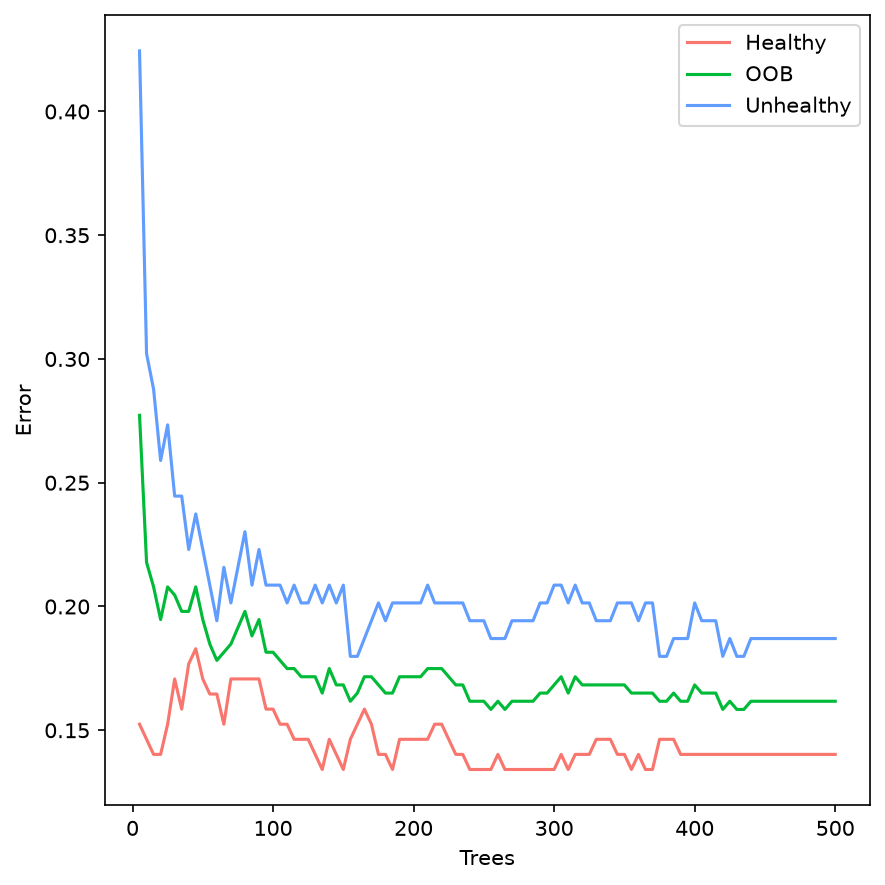

In [34]:
OOB_COLORS = {"Healthy": "#F8766D", "OOB": "#00BA38", "Unhealthy": "#619CFF"}

fig, ax = plt.subplots(figsize=(6, 6))
for name, color in OOB_COLORS.items():
    ax.plot(oob_error_data["Trees"], oob_error_data[name], color=color, label=name)
ax.set_xlabel("Trees")
ax.set_ylabel("Error")
ax.legend(loc="upper right")
fig.tight_layout()

## Tune `max_features` (the R `mtry`)

We fit one forest for each value from 1 to 10 and record its final OOB error. Each fit uses the same seed, so the comparison is reproducible. If several values tie for the minimum, `idxmin()` returns the smallest.

In [35]:
mtry_oob_error = {}
for mtry in range(1, 11):
    tuning_model = RandomForestClassifier(
        n_estimators=500,
        max_features=mtry,
        oob_score=True,
        random_state=SEED,
        n_jobs=-1,
    )
    tuning_model.fit(X.to_numpy(), y_array)
    mtry_oob_error[mtry] = 1 - tuning_model.oob_score_
mtry_results = pd.Series(mtry_oob_error, name="OOB error")
mtry_results

1     0.165017
2     0.161716
3     0.165017
4     0.171617
5     0.161716
6     0.174917
7     0.178218
8     0.178218
9     0.171617
10    0.178218
Name: OOB error, dtype: float64

In [ ]:
best_mtry = int(mtry_results.idxmin())
best_mtry

Refit the forest with the best `max_features`, keeping the proximities for the MDS plot later.

In [36]:
model = RandomForestClassifier(
    n_estimators=500,
    max_features=best_mtry,
    oob_score=True,
    random_state=SEED,
    n_jobs=-1,
)
model.fit(X.to_numpy(), y_array)
1 - model.oob_score_

0.16171617161716167

## Apply the model to new patients

The new patients use the same categories as the training data. `encode()` applies the same fixed categories, so the columns match.

In [37]:
new_patients = pd.DataFrame(
    {
        "age": [58, 35],
        "sex": ["M", "F"],
        "cp": ["4", "3"],
        "trestbps": [140, 115],
        "chol": [250, 190],
        "fbs": ["0", "0"],
        "restecg": ["0", "2"],
        "thalach": [130, 175],
        "exang": ["1", "0"],
        "oldpeak": [1.5, 0.0],
        "slope": ["2", "1"],
        "ca": ["1", "0"],
        "thal": ["7", "3"],
    },
    index=["patient.1", "patient.2"],
)
new_X = encode(new_patients).to_numpy()
predictions = pd.DataFrame(
    model.predict_proba(new_X),
    index=new_patients.index,
    columns=model.classes_,
)
predictions.insert(0, "predicted", model.predict(new_X))
predictions

,predicted,Healthy,Unhealthy
patient.1,Unhealthy,0.020,0.980
patient.2,Healthy,0.968,0.032


The `Healthy` and `Unhealthy` columns are the average class probabilities across trees. In R, `predict(type = "prob")` returns the share of trees voting for each class. These are close in concept but not identical.

## Visualize sample relationships with an MDS plot

1. Convert the proximity matrix into a distance matrix (`1 - proximity`).
2. Run classical MDS, implemented with `numpy` as in `cmdscale()`.
3. Compute the percent of variation each axis accounts for.

The sign of each MDS axis is arbitrary, so the plot may be a mirror image of the R version.

In [38]:
proximities = proximity_matrix(model, X.to_numpy())
distance = 1 - proximities


def classical_mds(distance_matrix):
    n = distance_matrix.shape[0]
    centering = np.eye(n) - np.ones((n, n)) / n
    b = -0.5 * centering @ (distance_matrix**2) @ centering
    eigenvalues, eigenvectors = np.linalg.eigh(b)
    order = np.argsort(eigenvalues)[::-1]
    return eigenvalues[order], eigenvectors[:, order]


eigenvalues, eigenvectors = classical_mds(distance)
pct_variation = np.round(eigenvalues / eigenvalues.sum() * 100, 1)
coords = eigenvectors[:, :2] * np.sqrt(np.clip(eigenvalues[:2], 0, None))

mds_data = pd.DataFrame(
    {
        "Sample": (np.arange(len(coords)) + 1).astype(str),
        "X": coords[:, 0],
        "Y": coords[:, 1],
        "Status": y_array,
    }
)
mds_data.head()

,Sample,X,Y,Status
0,1,0.002989,-0.029286,Healthy
1,2,0.229581,0.020011,Unhealthy
2,3,0.410008,0.086213,Unhealthy
3,4,-0.183091,0.106511,Healthy
4,5,-0.302645,-0.008048,Healthy


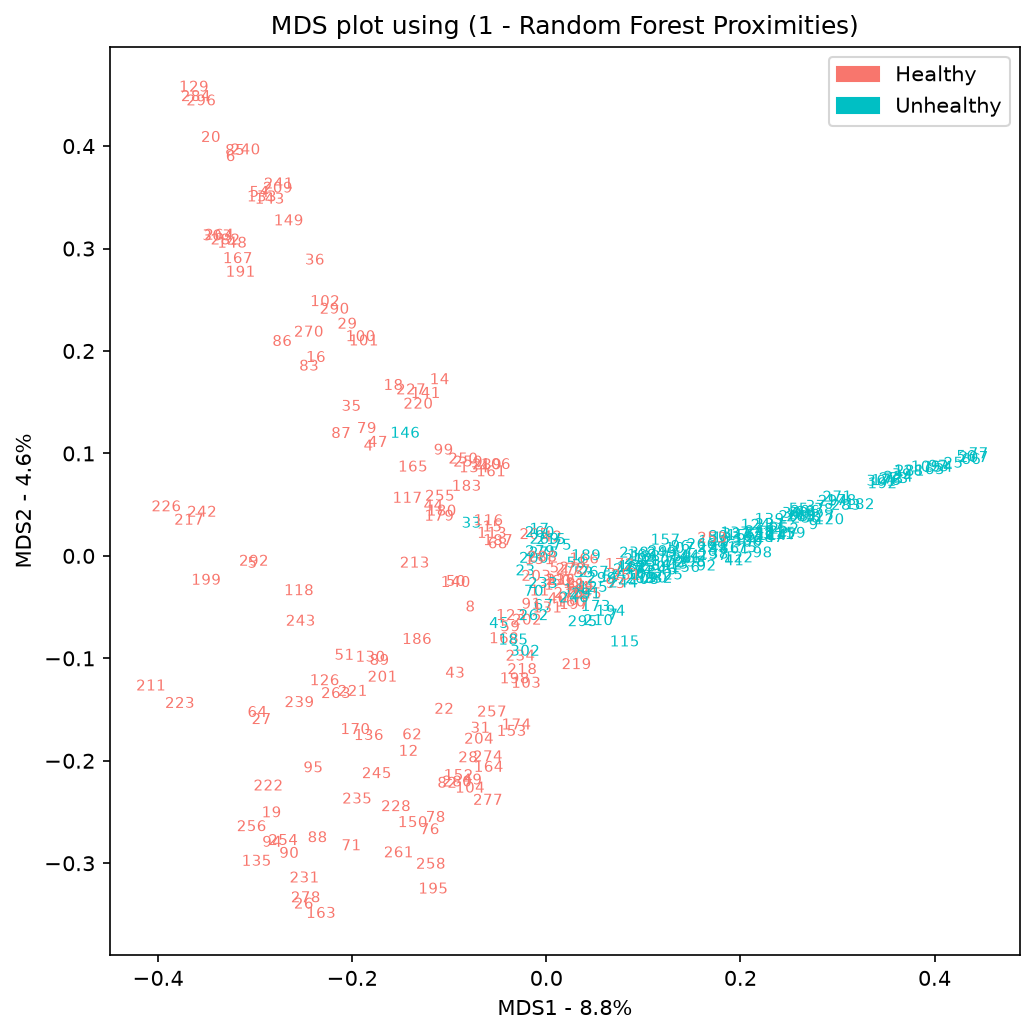

In [40]:
STATUS_COLORS = {"Healthy": "#F8766D", "Unhealthy": "#00BFC4"}

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(mds_data["X"], mds_data["Y"], color="none")
for row in mds_data.itertuples():
    ax.text(
        row.X,
        row.Y,
        row.Sample,
        color=STATUS_COLORS[row.Status],
        ha="center",
        va="center",
        fontsize=7,
    )
ax.set_xlabel(f"MDS1 - {pct_variation[0]}%")
ax.set_ylabel(f"MDS2 - {pct_variation[1]}%")
ax.set_title("MDS plot using (1 - Random Forest Proximities)")
ax.legend(
    handles=[Patch(color=color, label=name) for name, color in STATUS_COLORS.items()],
    loc="upper right",
)
fig.tight_layout()

In [41]:
# Save the MDS plot to a high-resolution PNG file
fig.savefig("mds_plot.png", dpi=150, bbox_inches="tight")